# Segmentação de clientes no Online Retail II

Objetivo: agrupar os clientes de um e-commerce britânico de presentes por comportamento de compra, de forma que cada grupo leve a uma ação comercial diferente.

O fluxo do notebook:

1. Carga e limpeza das transações, com cada regra contada e justificada
2. Construção das variáveis por cliente (RFM e variáveis de apoio)
3. Decisão de transformação e de quais variáveis entram no modelo
4. Baseline (K-Means) e dois modelos concorrentes (GMM e Hierárquico com Ward)
5. Escolha de K entre 2 e 10 com Elbow, Silhouette, Davies-Bouldin e Calinski-Harabasz
6. Teste de estabilidade com sementes e subamostras diferentes
7. Perfil dos segmentos e recomendações de ação

Dados: Online Retail II (UCI / Kaggle), transações de 01/12/2009 a 09/12/2011.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

SEED = 42
K_RANGE = range(2, 11)

# localiza o csv tanto rodando de notebooks/ quanto da raiz do projeto
caminho = next(p for p in [Path("../data/online_retail_II.csv"),
                           Path("data/online_retail_II.csv")] if p.exists())
RAIZ = caminho.absolute().parent.parent
FIG = RAIZ / "reports" / "figures"
OUT = RAIZ / "outputs"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)


def salvar(fig, nome):
    fig.savefig(FIG / f"{nome}.png", dpi=140, bbox_inches="tight")

## 2. Carga dos dados

In [2]:
df = pd.read_csv(caminho, parse_dates=["InvoiceDate"])
df = df.rename(columns={
    "Invoice": "invoice", "StockCode": "stock_code", "Description": "descricao",
    "Quantity": "quantidade", "InvoiceDate": "data", "Price": "preco",
    "Customer ID": "cliente_id", "Country": "pais",
})
df["invoice"] = df["invoice"].astype(str)
df["stock_code"] = df["stock_code"].astype(str)

print(f"{df.shape[0]:,} linhas, {df.shape[1]} colunas")
print(f"Período: {df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}")
df.head()

1,067,371 linhas, 8 colunas
Período: 01/12/2009 a 09/12/2011


,invoice,stock_code,descricao,quantidade,data,preco,cliente_id,pais
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 3. Limpeza

Cada regra abaixo é aplicada em sequência e o funil mostra quantas linhas cada uma remove. A ideia é que nenhuma exclusão seja silenciosa.

- **Duplicatas exatas**: linhas idênticas em todas as colunas, em geral o mesmo item lançado duas vezes na mesma fatura.
- **Cancelamentos** (fatura começando com "C"): saem da base de compras, mas guardo o valor devolvido por cliente para usar depois como variável de perfil.
- **Sem Customer ID**: não dá para segmentar quem não tem identificação.
- **Códigos que não são produto**: frete (POST), taxas bancárias, ajustes, amostras, vale-presente e afins. Os códigos de produto desta base começam com 5 dígitos.
- **Quantidade ou preço não positivos**: linhas de ajuste de estoque e preços zerados.

In [3]:
funil = [("Base original", len(df))]

df = df.drop_duplicates()
funil.append(("Sem duplicatas exatas", len(df)))

# cancelamentos ficam de lado para a taxa de devolução
eh_cancelamento = df["invoice"].str.startswith("C")
cancelamentos = df[eh_cancelamento].copy()
df = df[~eh_cancelamento]
funil.append(("Sem cancelamentos", len(df)))

df = df[df["cliente_id"].notna()]
funil.append(("Com Customer ID", len(df)))

so_produto = r"^\d{5}"
df = df[df["stock_code"].str.match(so_produto)]
funil.append(("Apenas códigos de produto", len(df)))

df = df[(df["quantidade"] > 0) & (df["preco"] > 0)]
funil.append(("Quantidade e preço positivos", len(df)))

cancelamentos = cancelamentos[cancelamentos["cliente_id"].notna()
                              & cancelamentos["stock_code"].str.match(so_produto)]

df["cliente_id"] = df["cliente_id"].astype(int)
cancelamentos["cliente_id"] = cancelamentos["cliente_id"].astype(int)
df["receita"] = df["quantidade"] * df["preco"]

funil = pd.DataFrame(funil, columns=["etapa", "linhas"])
funil["removidas"] = -funil["linhas"].diff().fillna(0).astype(int)
funil["% da base original"] = funil["linhas"] / funil.loc[0, "linhas"] * 100
funil

,etapa,linhas,removidas,% da base original
0,Base original,1067371,0,100.00
1,Sem duplicatas exatas,1033036,34335,96.78
2,Sem cancelamentos,1013932,19104,94.99
3,Com Customer ID,779495,234437,73.03
4,Apenas códigos de produto,776637,2858,72.76
5,Quantidade e preço positivos,776577,60,72.76


In [4]:
print(f"Clientes: {df['cliente_id'].nunique():,}")
print(f"Faturas: {df['invoice'].nunique():,}")
print(f"Receita total: £ {df['receita'].sum():,.0f}")

Clientes: 5,852
Faturas: 36,594
Receita total: £ 17,068,568


## 4. Variáveis por cliente

O ponto de partida é o RFM clássico:

- **Recência**: dias desde a última compra até a data de referência (o dia seguinte ao último dia da base)
- **Frequência**: número de faturas distintas
- **Monetário**: receita bruta acumulada em libras

Além dessas três, calculo variáveis de apoio que testo na seção 6 e uso para descrever os segmentos: ticket médio por fatura, quantidade de produtos distintos, tempo de casa, taxa de devolução e país.

In [5]:
data_ref = df["data"].max().normalize() + pd.Timedelta(days=1)
g = df.groupby("cliente_id")

clientes = pd.DataFrame({
    "ultima_compra": g["data"].max(),
    "primeira_compra": g["data"].min(),
    "frequencia": g["invoice"].nunique(),
    "monetario": g["receita"].sum(),
    "produtos_distintos": g["stock_code"].nunique(),
    "pais": g["pais"].agg(lambda s: s.mode().iat[0]),
})
clientes["recencia"] = (data_ref - clientes["ultima_compra"]).dt.days
clientes["tempo_de_casa"] = (data_ref - clientes["primeira_compra"]).dt.days
clientes["ticket_medio"] = clientes["monetario"] / clientes["frequencia"]

devolvido = (cancelamentos.assign(valor=(cancelamentos["quantidade"] * cancelamentos["preco"]).abs())
             .groupby("cliente_id")["valor"].sum())
clientes["taxa_devolucao"] = (devolvido.reindex(clientes.index).fillna(0)
                              / clientes["monetario"]).clip(upper=1)

RFM = ["recencia", "frequencia", "monetario"]
APOIO = ["ticket_medio", "produtos_distintos", "tempo_de_casa", "taxa_devolucao"]
print(f"{len(clientes):,} clientes")
clientes[RFM + APOIO].describe().T

5,852 clientes


,count,mean,std,min,25%,50%,75%,max
recencia,"5,852.00",199.73,208.52,0.00,25.00,95.00,379.00,738.00
frequencia,"5,852.00",6.25,12.75,1.00,1.00,3.00,7.00,373.00
monetario,"5,852.00","2,916.71","14,306.85",2.95,339.57,856.02,"2,241.03","580,987.04"
ticket_medio,"5,852.00",384.40,"1,254.73",2.95,176.15,277.87,410.56,"84,236.25"
produtos_distintos,"5,852.00",82.19,116.49,1.00,19.00,45.00,103.00,"2,546.00"
tempo_de_casa,"5,852.00",473.54,223.20,0.00,311.00,529.00,666.00,738.00
taxa_devolucao,"5,852.00",0.02,0.09,0.00,0.00,0.00,0.01,1.00


## 5. Exploração e transformação

In [6]:
ordenado = clientes["monetario"].sort_values(ascending=False)
top20 = ordenado.head(int(len(ordenado) * 0.2)).sum() / ordenado.sum()
top1 = ordenado.head(int(len(ordenado) * 0.01)).sum() / ordenado.sum()
print(f"20% dos clientes concentram {top20:.0%} da receita")
print(f"1% dos clientes concentra {top1:.0%} da receita")

20% dos clientes concentram 77% da receita
1% dos clientes concentra 32% da receita


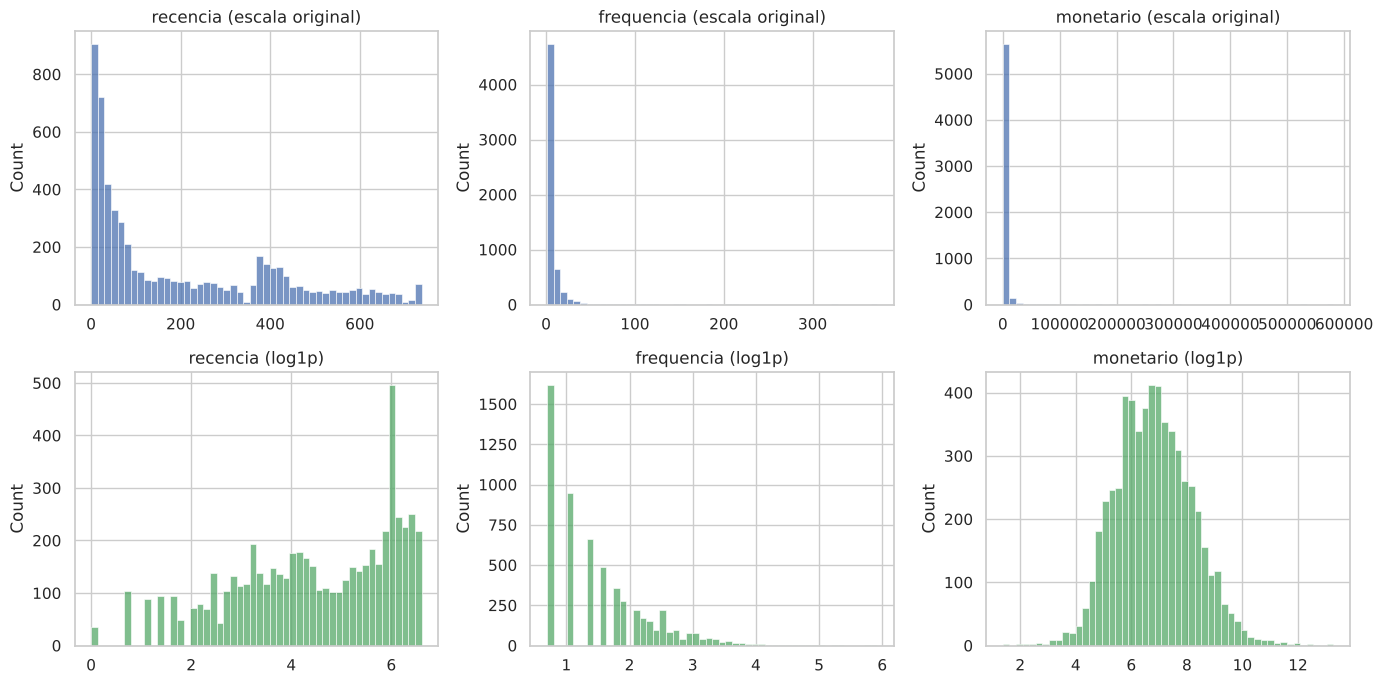

,original,log1p
recencia,0.89,-0.55
frequencia,12.04,1.00
monetario,25.33,0.27


In [7]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 7))
for j, col in enumerate(RFM):
    sns.histplot(clientes[col], bins=50, ax=eixos[0, j], color="#4c72b0")
    eixos[0, j].set_title(f"{col} (escala original)")
    sns.histplot(np.log1p(clientes[col]), bins=50, ax=eixos[1, j], color="#55a868")
    eixos[1, j].set_title(f"{col} (log1p)")
    eixos[0, j].set_xlabel("")
    eixos[1, j].set_xlabel("")
fig.tight_layout()
salvar(fig, "01_distribuicoes_rfm")
plt.show()

assimetria = pd.DataFrame({
    "original": clientes[RFM].skew(),
    "log1p": np.log1p(clientes[RFM]).skew(),
})
assimetria

As três variáveis são fortemente assimétricas à direita, principalmente frequência e monetário, o que é esperado em varejo: poucos clientes respondem por boa parte da receita. K-Means e GMM sofrem com isso, porque os clientes muito grandes puxam os centróides e viram praticamente um cluster à parte.

Decisão: aplicar `log1p` e depois `StandardScaler`. O log reduz bastante a assimetria e o escalonamento coloca as três variáveis na mesma régua de distância.

In [8]:
def preparar(colunas):
    return StandardScaler().fit_transform(np.log1p(clientes[colunas]))

X = preparar(RFM)
X.shape

(5852, 3)

## 6. Quais variáveis entram no modelo

Antes de comparar algoritmos, quero decidir se as variáveis de apoio (ticket médio e produtos distintos) ajudam ou só adicionam ruído. Olho primeiro a correlação, depois rodo o mesmo K-Means nos dois conjuntos e comparo qualidade e estabilidade.

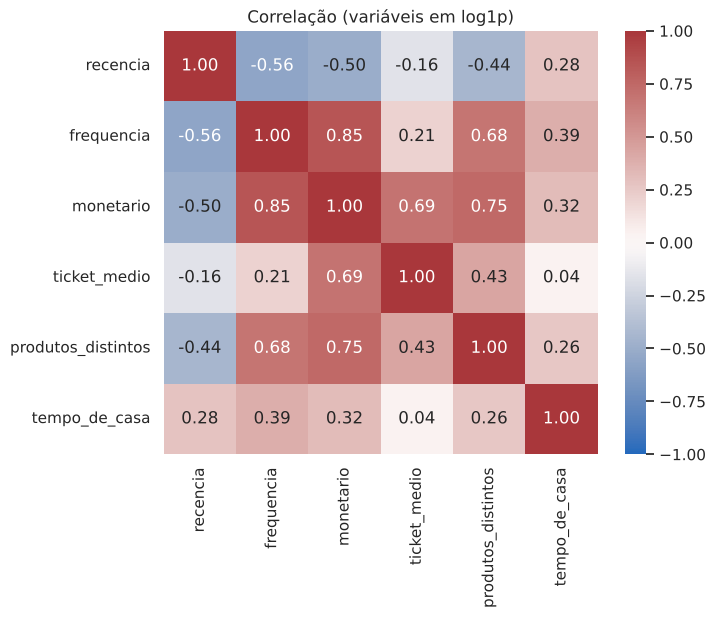

In [9]:
fig, ax = plt.subplots(figsize=(7, 5.5))
corr = np.log1p(clientes[RFM + ["ticket_medio", "produtos_distintos", "tempo_de_casa"]]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação (variáveis em log1p)")
salvar(fig, "02_correlacao")
plt.show()

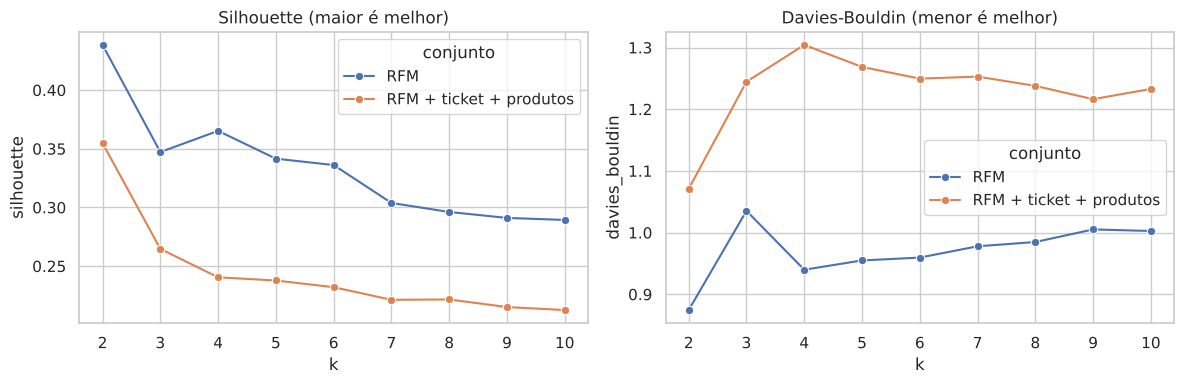

               conjunto  k  silhouette  davies_bouldin
                    RFM  4        0.37            0.94
RFM + ticket + produtos  4        0.24            1.30



,ARI médio,desvio,pior caso
RFM,0.96,0.03,0.91
RFM + ticket + produtos,0.95,0.04,0.86


In [10]:
def km(k, seed=SEED, n_init=10):
    return KMeans(n_clusters=k, n_init=n_init, random_state=seed)


def gmm(k, seed=SEED, n_init=5, cov="full"):
    return GaussianMixture(n_components=k, covariance_type=cov, n_init=n_init, random_state=seed)


def ward(k):
    return AgglomerativeClustering(n_clusters=k, linkage="ward")


def estabilidade_subamostra(construir, X, ref, n_rep=30, frac=0.8, seed=SEED):
    """Ajusta o modelo em subamostras e compara com a partição de referência (ARI)."""
    rng = np.random.default_rng(seed)
    resultados = []
    for _ in range(n_rep):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        rotulos = construir().fit_predict(X[idx])
        resultados.append(adjusted_rand_score(ref[idx], rotulos))
    return np.array(resultados)


conjuntos = {
    "RFM": RFM,
    "RFM + ticket + produtos": RFM + ["ticket_medio", "produtos_distintos"],
}

linhas = []
for nome, cols in conjuntos.items():
    Xc = preparar(cols)
    for k in K_RANGE:
        rotulos = km(k).fit_predict(Xc)
        linhas.append({"conjunto": nome, "k": k,
                       "silhouette": silhouette_score(Xc, rotulos),
                       "davies_bouldin": davies_bouldin_score(Xc, rotulos)})
comp_vars = pd.DataFrame(linhas)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=comp_vars, x="k", y="silhouette", hue="conjunto", marker="o", ax=eixos[0])
sns.lineplot(data=comp_vars, x="k", y="davies_bouldin", hue="conjunto", marker="o", ax=eixos[1])
eixos[0].set_title("Silhouette (maior é melhor)")
eixos[1].set_title("Davies-Bouldin (menor é melhor)")
fig.tight_layout()
salvar(fig, "03_conjuntos_de_variaveis")
plt.show()

K_TESTE = 4
estab = {}
for nome, cols in conjuntos.items():
    Xc = preparar(cols)
    ref = km(K_TESTE, n_init=50).fit_predict(Xc)
    estab[nome] = estabilidade_subamostra(lambda: km(K_TESTE), Xc, ref)
print(comp_vars[comp_vars["k"] == K_TESTE].round(4).to_string(index=False))
print()
pd.DataFrame({n: pd.Series(v).describe()[["mean", "std", "min"]] for n, v in estab.items()}).T.rename(
    columns={"mean": "ARI médio", "std": "desvio", "min": "pior caso"})

**Decisão: o modelo usa só RFM.**

Ticket médio e produtos distintos têm correlação alta com o monetário (0,69 e 0,75 em log), então repetem boa parte da informação que o RFM já traz. Ao incluí-los no K-Means com K=4, a silhouette cai de 0,37 para 0,24 e o Davies-Bouldin sobe de 0,94 para 1,30. A estabilidade quase não muda (ARI de 0,96 contra 0,95), ou seja, as variáveis extras não compram robustez.

Um cuidado: silhouette em espaços com número de dimensões diferente não é estritamente comparável, então não uso isso como argumento único. Pesam mais a redundância com o monetário e a facilidade de interpretar. As variáveis de apoio continuam no notebook e entram na descrição dos segmentos (seção 10), onde explicam o grupo sem distorcer a distância.

## 7. Escolha de K

Rodo os três algoritmos para K de 2 a 10 no mesmo espaço (RFM em log, padronizado) e comparo:

- **K-Means** (baseline): inércia (Elbow), Silhouette, Davies-Bouldin e Calinski-Harabasz
- **GMM**: as mesmas métricas, e testo os tipos de covariância pelo BIC
- **Hierárquico (Ward)**: as mesmas métricas, mais o dendrograma

Nenhuma dessas métricas decide sozinha. Silhouette tende a premiar K muito pequeno, e o Elbow quase nunca tem um cotovelo nítido em dado de comportamento. Vou procurar pontos onde as métricas concordam e depois checar se a partição é interpretável.

In [11]:
def varrer_k(nome, construir, X):
    linhas = []
    for k in K_RANGE:
        modelo = construir(k)
        rotulos = modelo.fit_predict(X)
        linha = {"modelo": nome, "k": k,
                 "silhouette": silhouette_score(X, rotulos),
                 "davies_bouldin": davies_bouldin_score(X, rotulos),
                 "calinski_harabasz": calinski_harabasz_score(X, rotulos)}
        if hasattr(modelo, "inertia_"):
            linha["inertia"] = modelo.inertia_
        if hasattr(modelo, "bic"):
            linha["bic"] = modelo.bic(X)
        linhas.append(linha)
    return pd.DataFrame(linhas)


varredura = pd.concat([
    varrer_k("K-Means (baseline)", km, X),
    varrer_k("GMM", gmm, X),
    varrer_k("Hierárquico (Ward)", ward, X),
], ignore_index=True)

varredura.pivot(index="k", columns="modelo", values="silhouette").round(4)

modelo,GMM,Hierárquico (Ward),K-Means (baseline)
k,,,
2,0.30,0.43,0.44
3,0.28,0.32,0.35
4,0.22,0.29,0.37
5,0.20,0.25,0.34
6,0.16,0.23,0.34
7,0.12,0.22,0.30
8,0.11,0.23,0.30
9,0.08,0.22,0.29
10,0.09,0.24,0.29


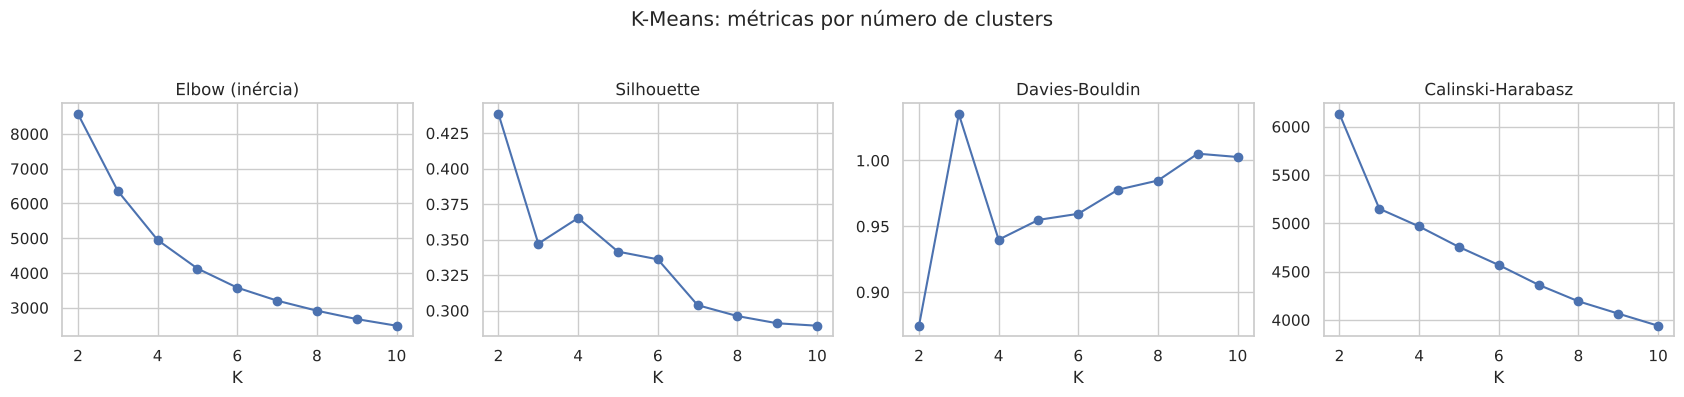

In [12]:
kmeans_v = varredura[varredura["modelo"] == "K-Means (baseline)"]
fig, eixos = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (col, titulo) in zip(eixos, [("inertia", "Elbow (inércia)"),
                                     ("silhouette", "Silhouette"),
                                     ("davies_bouldin", "Davies-Bouldin"),
                                     ("calinski_harabasz", "Calinski-Harabasz")]):
    ax.plot(kmeans_v["k"], kmeans_v[col], marker="o", color="#4c72b0")
    ax.set_title(titulo)
    ax.set_xlabel("K")
fig.suptitle("K-Means: métricas por número de clusters", y=1.04)
fig.tight_layout()
salvar(fig, "04_kmeans_escolha_k")
plt.show()

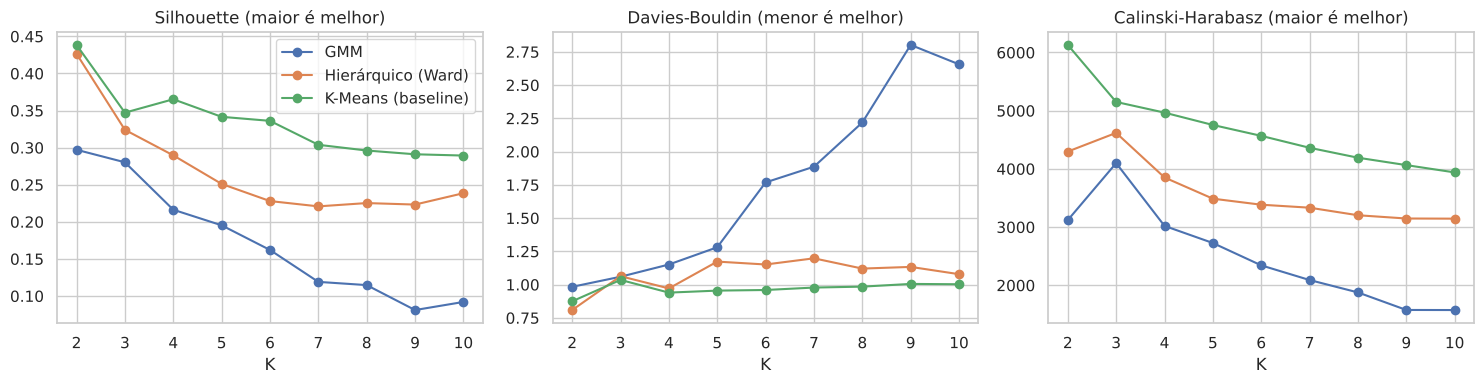

In [13]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for nome, sub in varredura.groupby("modelo"):
    eixos[0].plot(sub["k"], sub["silhouette"], marker="o", label=nome)
    eixos[1].plot(sub["k"], sub["davies_bouldin"], marker="o", label=nome)
    eixos[2].plot(sub["k"], sub["calinski_harabasz"], marker="o", label=nome)
eixos[0].set_title("Silhouette (maior é melhor)")
eixos[1].set_title("Davies-Bouldin (menor é melhor)")
eixos[2].set_title("Calinski-Harabasz (maior é melhor)")
for ax in eixos:
    ax.set_xlabel("K")
eixos[0].legend()
fig.tight_layout()
salvar(fig, "05_comparacao_modelos_por_k")
plt.show()

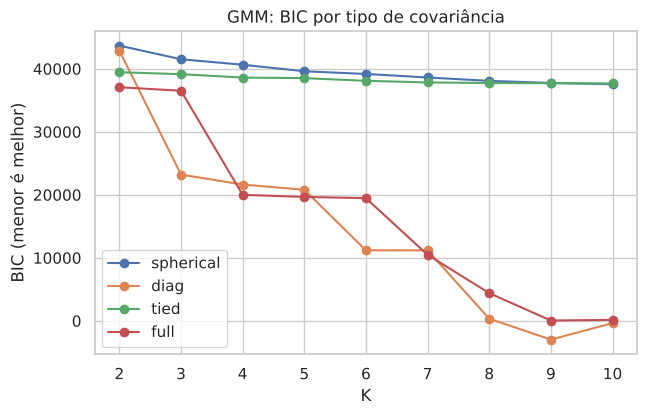

,spherical,diag,tied,full
2,"43,678.00","42,899.00","39,454.00","37,074.00"
3,"41,512.00","23,209.00","39,147.00","36,515.00"
4,"40,643.00","21,628.00","38,610.00","19,999.00"
5,"39,607.00","20,806.00","38,515.00","19,665.00"
6,"39,177.00","11,188.00","38,093.00","19,464.00"
7,"38,621.00","11,197.00","37,831.00","10,478.00"
8,"38,082.00",343.00,"37,749.00","4,395.00"
9,"37,750.00","-2,977.00","37,713.00",50.00
10,"37,545.00",-357.00,"37,678.00",158.00


In [14]:
# GMM: tipo de covariância pelo BIC
fig, ax = plt.subplots(figsize=(7, 4.2))
bic = {}
for cov in ["spherical", "diag", "tied", "full"]:
    bic[cov] = [gmm(k, cov=cov).fit(X).bic(X) for k in K_RANGE]
    ax.plot(list(K_RANGE), bic[cov], marker="o", label=cov)
ax.set_xlabel("K")
ax.set_ylabel("BIC (menor é melhor)")
ax.set_title("GMM: BIC por tipo de covariância")
ax.legend()
salvar(fig, "06_gmm_bic")
plt.show()

pd.DataFrame(bic, index=list(K_RANGE)).round(0)

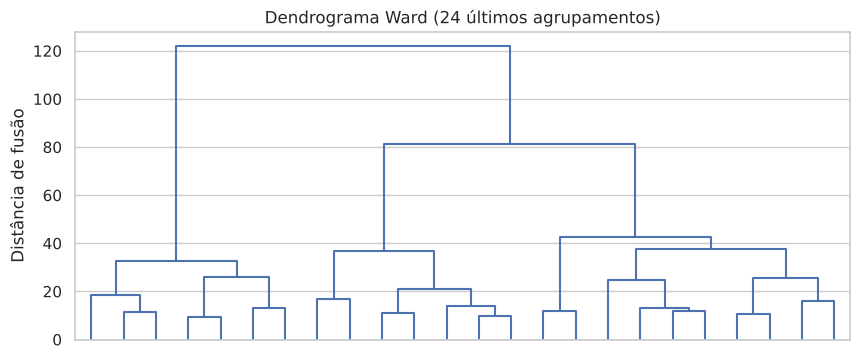

In [15]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=24, show_leaf_counts=True, no_labels=True,
           color_threshold=0, above_threshold_color="#4c72b0", ax=ax)
ax.set_title("Dendrograma Ward (24 últimos agrupamentos)")
ax.set_ylabel("Distância de fusão")
salvar(fig, "07_dendrograma")
plt.show()

**Decisão: K = 4.**

- **K = 2** tem a maior silhouette (0,44 no K-Means e 0,43 no Ward), mas só separa clientes ativos de inativos. O negócio já sabe disso e não há ação diferente por grupo.
- **K-Means**: K=4 é um máximo local. A silhouette sobe de 0,35 (K=3) para 0,37 (K=4) e o Davies-Bouldin cai de 1,04 para 0,94. De K=5 em diante as duas métricas pioram aos poucos.
- **Elbow**: a inércia cai de forma contínua e não há cotovelo nítido. A queda é de 22% de 3 para 4, 17% de 4 para 5 e 13% de 5 para 6, então o Elbow sozinho não decide. O Calinski-Harabasz diminui a cada K e também não ajuda a escolher.
- **Ward**: o dendrograma mostra saltos claros nos cortes de 2 e 3 clusters. O corte em 4 é menos nítido, e a silhouette do Ward cai de 0,32 para 0,29 entre K=3 e K=4.
- **GMM**: a silhouette é a pior dos três em todos os valores de K. O BIC com covariância completa despenca de 36.515 (K=3) para 19.999 (K=4) e segue caindo até valores próximos de zero em K=9. Esse comportamento é suspeito: frequência é um número inteiro e muitos clientes têm valores idênticos (uma única fatura, por exemplo), o que provavelmente deixa o GMM criar componentes muito estreitos com verossimilhança altíssima. Por isso não usei o BIC para escolher K.

K=4 é o ponto em que o K-Means tem o melhor equilíbrio entre as métricas e ainda gera segmentos que o time comercial consegue tratar de forma diferente. É uma escolha de julgamento apoiada nas métricas, não um ótimo objetivo.

## 8. Comparação dos modelos

Com K fixado, comparo os três modelos em qualidade interna, equilíbrio de tamanho e acordo entre eles. A estabilidade vem na seção seguinte.

In [16]:
K = 4

ref_km = km(K, n_init=50).fit_predict(X)
gmm_final = gmm(K, n_init=20).fit(X)
ref_gmm = gmm_final.predict(X)
ref_ward = ward(K).fit_predict(X)

particoes = {
    "K-Means (baseline)": ref_km,
    "GMM": ref_gmm,
    "Hierárquico (Ward)": ref_ward,
}

linhas = []
for nome, rot in particoes.items():
    tamanhos = pd.Series(rot).value_counts(normalize=True)
    linhas.append({
        "modelo": nome,
        "silhouette": silhouette_score(X, rot),
        "davies_bouldin": davies_bouldin_score(X, rot),
        "calinski_harabasz": calinski_harabasz_score(X, rot),
        "menor cluster (%)": tamanhos.min() * 100,
        "maior cluster (%)": tamanhos.max() * 100,
    })
tabela = pd.DataFrame(linhas).set_index("modelo")
tabela

,silhouette,davies_bouldin,calinski_harabasz,menor cluster (%),maior cluster (%)
modelo,,,,,
K-Means (baseline),0.37,0.94,"4,966.65",18.97,35.10
GMM,0.22,1.15,"3,020.42",15.82,37.70
Hierárquico (Ward),0.29,0.97,"3,852.39",6.99,39.29


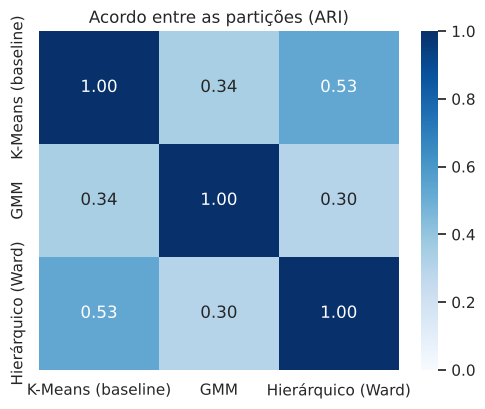

,K-Means (baseline),GMM,Hierárquico (Ward)
K-Means (baseline),1.00,0.34,0.53
GMM,0.34,1.00,0.30
Hierárquico (Ward),0.53,0.30,1.00


In [17]:
nomes = list(particoes)
acordo = pd.DataFrame(
    [[adjusted_rand_score(particoes[a], particoes[b]) for b in nomes] for a in nomes],
    index=nomes, columns=nomes)
fig, ax = plt.subplots(figsize=(5.8, 4.4))
sns.heatmap(acordo, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Acordo entre as partições (ARI)")
salvar(fig, "08_acordo_modelos")
plt.show()
acordo.round(2)

## 9. Estabilidade

Uma segmentação só serve se ela se repete. Testo duas coisas, sempre medindo o Adjusted Rand Index (ARI) contra a partição de referência, onde 1 significa partições idênticas:

- **Sementes**: reajusto o modelo com 30 sementes diferentes, usando uma única inicialização, que é o pior caso. O Ward é determinístico e não entra.
- **Subamostras**: reajusto em 30 amostras aleatórias de 80% dos clientes e comparo os rótulos desses mesmos clientes com a referência.

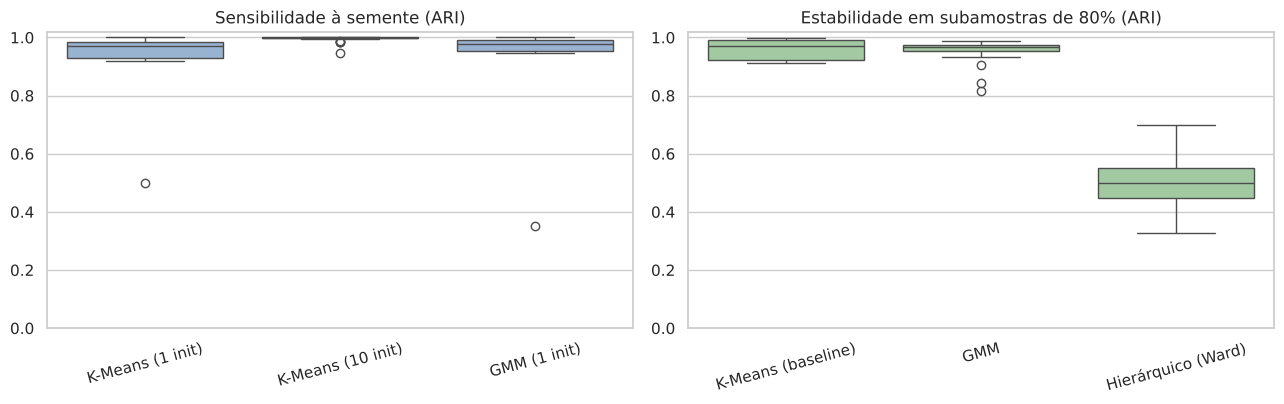

ARI médio  desvio  pior caso
sementes    K-Means (1 init)         0.95    0.09       0.50
            K-Means (10 init)        1.00    0.01       0.95
            GMM (1 init)             0.95    0.12       0.35
subamostras K-Means (baseline)       0.96    0.03       0.91
            GMM                      0.96    0.04       0.82
            Hierárquico (Ward)       0.50    0.09       0.33

In [18]:
N_REP = 30

sementes = {
    "K-Means (1 init)": [adjusted_rand_score(ref_km, km(K, seed=s, n_init=1).fit_predict(X)) for s in range(N_REP)],
    "K-Means (10 init)": [adjusted_rand_score(ref_km, km(K, seed=s, n_init=10).fit_predict(X)) for s in range(N_REP)],
    "GMM (1 init)": [adjusted_rand_score(ref_gmm, gmm(K, seed=s, n_init=1).fit_predict(X)) for s in range(N_REP)],
}

subamostras = {
    "K-Means (baseline)": estabilidade_subamostra(lambda: km(K), X, ref_km, N_REP),
    "GMM": estabilidade_subamostra(lambda: gmm(K), X, ref_gmm, N_REP),
    "Hierárquico (Ward)": estabilidade_subamostra(lambda: ward(K), X, ref_ward, N_REP),
}

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(data=pd.DataFrame(sementes), ax=eixos[0], color="#8fb3d9")
eixos[0].set_title("Sensibilidade à semente (ARI)")
eixos[0].set_ylim(0, 1.02)
sns.boxplot(data=pd.DataFrame(subamostras), ax=eixos[1], color="#9ccf9c")
eixos[1].set_title("Estabilidade em subamostras de 80% (ARI)")
eixos[1].set_ylim(0, 1.02)
for ax in eixos:
    ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
salvar(fig, "09_estabilidade")
plt.show()

resumo_estab = pd.concat({
    "sementes": pd.DataFrame(sementes).describe().T[["mean", "std", "min"]],
    "subamostras": pd.DataFrame(subamostras).describe().T[["mean", "std", "min"]],
}).rename(columns={"mean": "ARI médio", "std": "desvio", "min": "pior caso"})
resumo_estab

**Resultado da comparação**

O baseline não foi superado. Com K=4:

- **K-Means**: melhor silhouette (0,37), Davies-Bouldin (0,94) e Calinski-Harabasz (4.967) dos três, e o menor cluster tem 19% dos clientes. Com 10 inicializações é praticamente insensível à semente (ARI médio de 1,00, pior caso de 0,95) e se mantém em subamostras (0,96). Com uma única inicialização o pior caso cai para 0,50, por isso uso `n_init=10`.
- **GMM**: estabilidade parecida em subamostras (0,96), mas métricas piores e mais sensível à semente (pior caso de 0,35 com uma inicialização). Parte dessa diferença vem do método de avaliação: silhouette e Davies-Bouldin medem separação com distância euclidiana, o que favorece o K-Means por construção. Mesmo assim, o GMM não trouxe nenhuma vantagem que justifique a complexidade extra.
- **Ward**: métricas intermediárias, mas a partição muda bastante quando a amostra muda (ARI de 0,50 em subamostras) e um dos clusters tem só 7% dos clientes.

O acordo entre as partições é baixo (ARI de 0,34 entre K-Means e GMM, 0,53 entre K-Means e Ward, 0,30 entre GMM e Ward). Isso indica que os clientes formam um contínuo e não blocos bem separados: cada algoritmo corta esse contínuo em lugares um pouco diferentes. A projeção PCA da seção seguinte mostra o mesmo. Por isso estabilidade e leitura de negócio pesam tanto na decisão.

**Modelo escolhido: K-Means com K=4 e 10 inicializações.**

## 10. Perfil dos segmentos

Os rótulos de cluster são arbitrários, então reordeno os segmentos pela mediana de receita, do maior para o menor. Assim o segmento 0 é sempre o de maior valor e a numeração não muda se o notebook for reexecutado.

In [19]:
MODELO_FINAL = "K-Means (baseline)"
rotulos = particoes[MODELO_FINAL]

ordem = (clientes.assign(c=rotulos).groupby("c")["monetario"]
         .median().sort_values(ascending=False).index)
mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
clientes["segmento"] = pd.Series(rotulos, index=clientes.index).map(mapa)

perfil = clientes.groupby("segmento").agg(
    clientes=("recencia", "size"),
    recencia=("recencia", "median"),
    frequencia=("frequencia", "median"),
    monetario=("monetario", "median"),
    ticket_medio=("ticket_medio", "median"),
    produtos=("produtos_distintos", "median"),
    tempo_de_casa=("tempo_de_casa", "median"),
    taxa_devolucao_media=("taxa_devolucao", "mean"),
    receita_total=("monetario", "sum"),
)
perfil["% clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil["% receita"] = perfil["receita_total"] / perfil["receita_total"].sum() * 100
perfil["% Reino Unido"] = clientes.groupby("segmento")["pais"].apply(lambda s: (s == "United Kingdom").mean() * 100)
perfil.drop(columns="receita_total")

,clientes,recencia,frequencia,monetario,ticket_medio,produtos,tempo_de_casa,taxa_devolucao_media,% clientes,% receita,% Reino Unido
segmento,,,,,,,,,,,
0,1110,15.00,13.00,"5,117.68",363.32,168.00,681.00,0.02,18.97,71.58,90.99
1,1468,157.00,5.00,"1,580.42",320.74,69.00,621.00,0.03,25.09,18.46,89.92
2,1220,23.00,3.00,707.66,252.65,43.00,212.00,0.02,20.85,5.87,90.57
3,2054,398.00,1.00,291.43,204.25,18.00,444.00,0.03,35.10,4.09,92.45


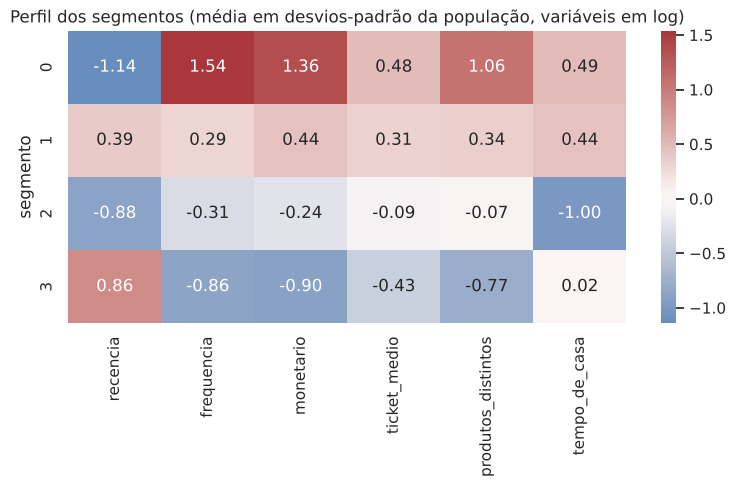

In [20]:
cols_heat = RFM + ["ticket_medio", "produtos_distintos", "tempo_de_casa"]
logs = np.log1p(clientes[cols_heat])
z = (logs - logs.mean()) / logs.std()
mapa_calor = z.groupby(clientes["segmento"]).mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(mapa_calor, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Perfil dos segmentos (média em desvios-padrão da população, variáveis em log)")
ax.set_xlabel("")
salvar(fig, "10_perfil_segmentos")
plt.show()

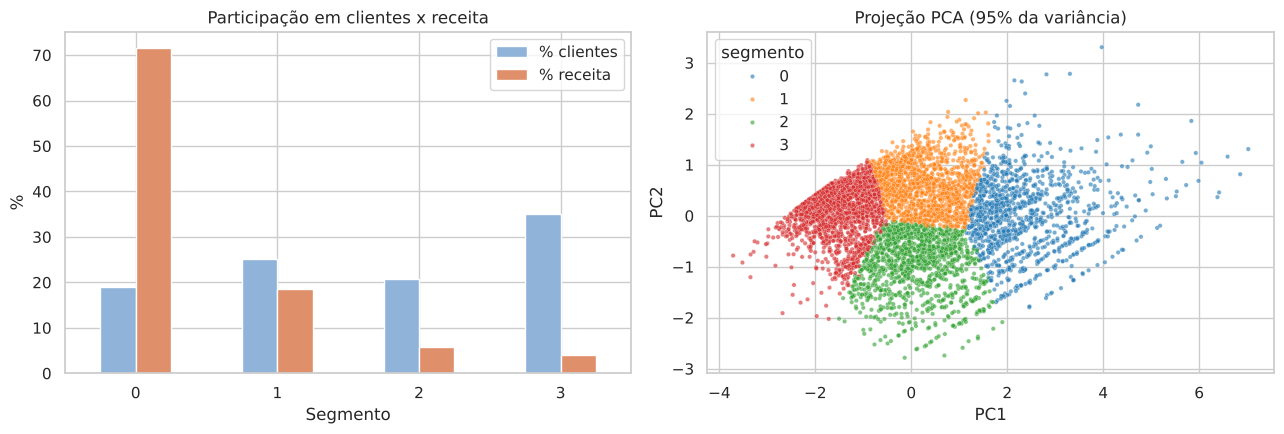

In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

dados = perfil[["% clientes", "% receita"]]
dados.plot.bar(ax=eixos[0], color=["#8fb3d9", "#e08f6b"], rot=0)
eixos[0].set_title("Participação em clientes x receita")
eixos[0].set_xlabel("Segmento")
eixos[0].set_ylabel("%")

pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(X)
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=clientes["segmento"], palette="tab10",
                s=10, alpha=0.6, ax=eixos[1])
eixos[1].set_title(f"Projeção PCA ({pca.explained_variance_ratio_.sum():.0%} da variância)")
eixos[1].set_xlabel("PC1")
eixos[1].set_ylabel("PC2")
fig.tight_layout()
salvar(fig, "11_receita_e_pca")
plt.show()

**Leitura dos segmentos**

- **Segmento 0, clientes-chave** (19% dos clientes, 72% da receita): última compra há 15 dias em mediana, 13 faturas, £ 5.118 acumulados, 168 produtos distintos e quase dois anos de casa (681 dias). A base tem muitos atacadistas, então é provável que boa parte desse grupo seja B2B.
- **Segmento 1, fiéis em esfriamento** (25%, 18% da receita): compram com recorrência (5 faturas, £ 1.580) e têm longo histórico (621 dias), mas a última compra foi há 157 dias.
- **Segmento 2, novos em desenvolvimento** (21%, 6% da receita): compraram há pouco (23 dias), mas estão na base há só 212 dias e ainda têm poucas faturas (3) e valor baixo (£ 708).
- **Segmento 3, inativos** (35%, 4% da receita): mediana de uma única fatura de £ 291, feita há 398 dias.

Dois pontos de atenção. A concentração é alta: o segmento 0 tem 19% dos clientes e 72% da receita, então perder um desses clientes pesa muito. Além disso, taxa de devolução (2% a 3% em média) e país (cerca de 90% Reino Unido em todos os segmentos) não diferenciam os grupos. O que separa os segmentos é o comportamento de compra.

## 11. Recomendações por segmento

| Segmento | Objetivo | Ação sugerida |
|---|---|---|
| 0. Clientes-chave | Reter | Contato direto ou gerente de conta, condições de volume, acesso antecipado a lançamentos e coleções sazonais. Tratar queda de frequência como alerta. |
| 1. Fiéis em esfriamento | Reativar antes de perder | Campanha de retorno baseada nos produtos que já compraram, lembrete sazonal e oferta com prazo. |
| 2. Novos em desenvolvimento | Levar à segunda e à terceira compra | Sequência de relacionamento após a primeira compra, sugestão de itens complementares e incentivo para a próxima fatura. |
| 3. Inativos | Reativar com custo baixo | E-mail automático de reativação sem desconto agressivo. Quem não responder sai da comunicação ativa. |

Essas são hipóteses de ação. O notebook não mede o efeito delas, e o caminho natural é testar cada uma com grupo de controle.

## 12. Exportação

In [22]:
NOMES = {0: "Clientes-chave", 1: "Fiéis em esfriamento", 2: "Novos em desenvolvimento", 3: "Inativos"}
clientes["segmento_nome"] = clientes["segmento"].map(NOMES)

saida = clientes.reset_index()[["cliente_id", "segmento", "segmento_nome", "recencia", "frequencia",
                                "monetario", "ticket_medio", "produtos_distintos",
                                "tempo_de_casa", "taxa_devolucao", "pais"]]
saida.to_csv(OUT / "clientes_segmentados.csv", index=False)
perfil.to_csv(OUT / "perfil_segmentos.csv")
varredura.to_csv(OUT / "metricas_por_k.csv", index=False)
print(f"{len(saida):,} clientes exportados para outputs/")

5,852 clientes exportados para outputs/


## 13. Robustez a clientes extremos

Dois grupos de clientes podem pesar mais do que o resto na segmentação: os 58 do 1% de maior receita (o maior gastou £ 581 mil) e os 39 com devolução acima de 50% do que compraram. Para saber se os segmentos dependem deles, reajusto o K-Means (K=4, `n_init=10`) sem esses clientes, reordeno os segmentos por valor e comparo com a partição de referência pelo ARI.

Como controle, repito o teste removendo 58 clientes aleatórios. Assim dá para separar o efeito de "tirar clientes" do efeito de "tirar justamente esses clientes".

In [23]:
def reajustar_sem(remover):
    """Reajusta o K-Means sem os clientes em `remover` e compara com a partição de referência."""
    resto = clientes.drop(index=remover)
    rotulos = km(4).fit_predict(StandardScaler().fit_transform(np.log1p(resto[RFM])))
    ordem = resto.assign(c=rotulos).groupby("c")["monetario"].median().sort_values(ascending=False).index
    novo = pd.Series(rotulos, index=resto.index).map({a: i for i, a in enumerate(ordem)})
    ref = clientes.loc[resto.index, "segmento"]
    return adjusted_rand_score(ref, novo), (novo == ref).mean(), novo, ref


topo = clientes["monetario"].nlargest(int(len(clientes) * 0.01)).index
devolucao_alta = clientes.index[clientes["taxa_devolucao"] > 0.5]
print(f"1% de maior receita: {len(topo)} | devolução > 50%: {len(devolucao_alta)} "
      f"| nos dois grupos: {len(topo.intersection(devolucao_alta))}\n")

cenarios = {
    "Sem o 1% de maior receita": topo,
    "Sem devolução > 50%": devolucao_alta,
    "Sem os dois grupos": topo.union(devolucao_alta),
}
linhas = []
for nome, remover in cenarios.items():
    ari, igual, _, _ = reajustar_sem(remover)
    linhas.append({"cenário": nome, "removidos": len(remover), "ARI": ari, "fração no mesmo segmento": igual})

rng = np.random.default_rng(SEED)
aleatorios = [reajustar_sem(rng.choice(clientes.index, len(topo), replace=False))[0] for _ in range(30)]
linhas.append({"cenário": "Controle: 58 aleatórios (média de 30)", "removidos": len(topo),
               "ARI": np.mean(aleatorios), "fração no mesmo segmento": np.nan})
print(pd.DataFrame(linhas).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

_, _, novo, ref = reajustar_sem(topo)
print("\nOnde os clientes mudam (sem o 1% de maior receita): linhas = referência, colunas = reajuste")
print(pd.crosstab(ref, novo).to_string())

1% de maior receita: 58 | devolução > 50%: 39 | nos dois grupos: 3



                              cenário  removidos   ARI  fração no mesmo segmento
            Sem o 1% de maior receita         58 0.895                     0.957
                  Sem devolução > 50%         39 0.999                     1.000
                   Sem os dois grupos         94 0.896                     0.957
Controle: 58 aleatórios (média de 30)         58 0.998                       NaN

Onde os clientes mudam (sem o 1% de maior receita): linhas = referência, colunas = reajuste
col_0        0     1     2     3
segmento                        
0         1056     0     0     0
1          112  1344     8     0
2           28     3  1187     2
3            0    91     4  1959


**Resultado**

- **Devolução alta não pesa.** Sem os 39 clientes, o ARI é 0,999 e nenhum cliente muda de segmento.
- **O topo de receita pesa um pouco.** Sem o 1% de maior receita, o ARI cai para 0,90 e 96% dos clientes continuam no mesmo segmento. Remover 58 clientes aleatórios mantém o ARI em 0,998, então o efeito vem de serem justamente os maiores clientes.
- **A mudança está nas fronteiras.** As trocas são poucas e pontuais: 112 clientes de "fiéis em esfriamento" passam a "clientes-chave", 91 de "inativos" passam a "fiéis em esfriamento" e 28 de "novos" passam a "clientes-chave". Ninguém vai de "inativos" a "clientes-chave" nem o contrário, e nenhum "cliente-chave" original sai do grupo.
- **O perfil se mantém.** Continuam quatro grupos, na mesma ordem de valor, com tamanhos dentro de 2 pontos percentuais dos originais. A mediana de recência do segmento 1 sobe de 157 para 185 dias.

Conclusão: os segmentos não dependem dos clientes extremos, mas os cortes entre segmentos se deslocam um pouco quando o topo sai. Isso combina com o que a seção 8 já mostrou: os clientes formam um contínuo, e os limites entre segmentos são uma convenção útil, não uma fronteira natural.

## 14. Limitações e próximos passos

- **Sazonalidade**: a loja vende presentes e tem pico no fim do ano, e a base termina em 09/12/2011. Quem compra só nessa época pode ter sido lido como inativo, então o segmento 1 provavelmente inclui compradores sazonais.
- **Um único corte no tempo**: não validei se os segmentos se mantêm entre períodos, por exemplo treinando com 2010 e aplicando em 2011. É o próximo passo mais valioso.
- **Contínuo sem fronteiras naturais**: a silhouette de 0,37 é moderada e o acordo entre algoritmos é baixo. Os segmentos são uma partição útil, não grupos naturais bem separados.
- **Clientes sem identificação**: cerca de 23% das linhas de venda não têm Customer ID e ficam de fora. Não há como saber se esses compradores se comportam como os identificados.
- **Mistura de B2B e B2C**: a base tem muitos atacadistas e não há coluna que os separe. Um modelo específico para cada tipo poderia dar segmentos mais claros.
- **Clientes extremos**: testei na seção 13. Sem os 39 clientes com devolução alta nada muda (ARI 0,999). Sem o 1% de maior receita o ARI é 0,90: os segmentos se mantêm, mas as fronteiras entre segmentos se deslocam. Não testei outras formas de tratar outliers, como winsorização.
- **Próximos passos**: validação temporal, estimativa de CLV, modelo de churn por segmento e teste das ações propostas.